# AI Game Generator: Analisis Data, Modeling, dan GenAI
**Capstone Project Data Science & Generative AI (Celerates)**

**Masalah.** Acara kumpul (kajian, kelas, arisan, sosialisasi desa) sering berakhir dengan semua orang sibuk
main HP sendiri-sendiri. Game party yang ada kaku: pilihannya itu-itu saja (mis. cuma satu jenis game),
harus gonta-ganti aplikasi, dan tidak bisa menyesuaikan materi acara.

**Solusi.** Aplikasi yang (1) membaca tren minat publik terhadap tiap jenis game dari data **real**
(Wikipedia pageviews + Google Trends Indonesia), (2) memakai data **real** BoardGameGeek untuk menilai daya tarik
game baru yang belum punya riwayat (cold start), (3) mencampur keduanya dengan log permintaan di aplikasi yang
**mulai dari nol** dan terus bertambah, lalu (4) memakai agent LangChain untuk membuat game dari dokumen acara dan
langsung memberi link room host + peserta.

| Sumber | Status | Isi |
|---|---|---|
| Wikipedia Pageviews API | real | view mingguan artikel yang mewakili tiap jenis game (21 seri) |
| Google Trends Indonesia | real | indeks minat pencarian 0-100 per keyword game (15 seri) |
| BoardGameGeek (TidyTuesday 2022) | real | 4.911 game party: profil + jumlah rating |
| Log request in-app | real, mulai 0 | belum ada saat notebook ini dibuat -> bagian 7 memakai **SIMULASI berlabel** |
| TikTok / X | tidak dipakai | tidak ada API gratis yang stabil |

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .3})
from core.catalog import GAMES, GAME_BY_ID
from core.real_sources import GAME_SOURCES, CONTEXT_WIKI
NAMES = {g['id']: g['name'] for g in GAMES} | {f'ctx:{k}': f'[konteks] {k}' for k in CONTEXT_WIKI}
REAL = ROOT / 'data' / 'real'

## 1. Pemahaman Data
### 1.1 Sinyal tren real (Wikipedia + Google Trends)

In [2]:
wiki = pd.read_csv(REAL / 'wiki_weekly.csv', parse_dates=['week'])
gt = pd.read_csv(REAL / 'gtrends_weekly.csv', parse_dates=['week'])
log = json.loads((REAL / 'fetch_log.json').read_text())
print('wiki   :', wiki.shape, '| seri:', wiki.game_id.nunique(), '| minggu:', wiki.week.min().date(), '->', wiki.week.max().date())
print('gtrends:', gt.shape, '| seri:', gt.game_id.nunique())
print('diambil:', log['run_at'])
pd.DataFrame([{'game': NAMES.get(g, g), 'artikel Wikipedia': ', '.join(s['wiki']), 'keyword Google Trends': s['gtrends']}
              for g, s in GAME_SOURCES.items()])

wiki   : (2078, 4) | seri: 21 | minggu: 2024-12-02 -> 2026-11-16
gtrends: (1560, 4) | seri: 15
diambil: 2026-11-26T12:14:23+00:00


,game,artikel Wikipedia,keyword Google Trends
0,Kuis Kilat,en:Kahoot!,kahoot
1,Fakta atau Hoaks,"en:Fact-checking, id:Hoaks",hoaks
2,Satu Frekuensi,en:Family_Feud,family 100
3,Tebak Angka,"en:Wits_&_Wagers, en:Fermi_problem",tebak angka
4,Adu Receh,en:Cards_Against_Humanity,jokes bapak bapak
5,Debat Kilat,"en:Debate, id:Debat",debat
6,Survival Kuis,en:Squid_Game,squid game
7,Kubu vs Kubu,"en:Quiz_bowl, id:Cerdas_cermat",cerdas cermat
8,Tebak Emoji,en:Emoji,tebak emoji
9,Siapa Paling,en:Never_have_I_ever,never have i ever


In [3]:
desc = wiki.groupby('game_id')['wiki_views'].agg(['count', 'mean', 'median', 'min', 'max']).round(0)
desc.index = desc.index.map(lambda g: NAMES.get(g, g)); desc.sort_values('median', ascending=False)

,count,mean,median,min,max
game_id,,,,,
Tebak Kata Kunci,103,170313.0,167156.0,65215,274798
Survival Kuis,103,92695.0,29539.0,12352,1423712
Caption Meme,103,16330.0,16117.0,11728,22745
Tebak Emoji,103,12515.0,12980.0,7585,29271
[konteks] Among Us,103,13013.0,12225.0,8903,24095
Mitos vs Sains,103,10778.0,10207.0,5940,42991
Satu Frekuensi,103,8671.0,8410.0,7009,12829
[konteks] Mafia,103,9091.0,8209.0,4727,21410
Harga Pas,103,7811.0,7544.0,5414,14165


In [4]:
gt.groupby('keyword')['google_trends'].describe()[['count','mean','50%','min','max']].round(1)

,count,mean,50%,min,max
keyword,,,,,
cerdas cermat,104.0,10.9,10.0,3.0,100.0
cerita berantai,104.0,1.7,0.0,0.0,100.0
debat,104.0,63.3,65.0,39.0,100.0
family 100,104.0,44.2,42.0,20.0,100.0
hoaks,104.0,46.7,47.0,8.0,100.0
jokes bapak bapak,104.0,49.8,50.0,29.0,100.0
kahoot,104.0,52.4,54.5,6.0,100.0
meme,104.0,82.9,83.5,69.0,100.0
mitos atau fakta,104.0,58.1,56.0,31.0,100.0


### 1.2 BoardGameGeek (data real game party)

In [5]:
from core.appeal import load_bgg
bgg = load_bgg()
print(bgg.shape); bgg[['name','yearpublished','minplayers','maxplayers','playingtime','minage','users_rated','average']].head()

(4911, 15)


,name,yearpublished,minplayers,maxplayers,playingtime,minage,users_rated,average
0,Codenames,2015,2,8,15,14,74419,7.60
1,Love Letter,2012,2,4,20,10,59467,7.23
2,Wingspan,2019,1,5,70,10,56079,8.10
3,Dixit,2008,3,6,30,8,54497,7.24
4,Citadels,2000,2,8,60,10,50181,7.08


In [6]:
info = pd.DataFrame({'missing': bgg.isna().sum(), 'unique': bgg.drop(columns=['categories','mechanics']).nunique()})
print(info.T); bgg[['minplayers','maxplayers','playingtime','minage','users_rated','average','bayes_average']].describe().T.round(1)

         average  bayes_average  categories      id  maxplayers  mechanics  \
missing      0.0            0.0         0.0     0.0         0.0        0.0   
unique     490.0          940.0         NaN  4911.0        46.0        NaN   

         minage  minplayers    name   owned  playingtime    rank  users_rated  \
missing     0.0         0.0     0.0     0.0          0.0     0.0          0.0   
unique     21.0        11.0  4870.0  1764.0         50.0  4911.0       1265.0   

         wishing  yearpublished  
missing      0.0            0.0  
unique     700.0           99.0  


,count,mean,std,min,25%,50%,75%,max
minplayers,4911.0,2.4,0.9,0.0,2.0,2.0,3.0,10.0
maxplayers,4911.0,8.6,19.5,0.0,4.0,6.0,8.0,999.0
playingtime,4911.0,47.0,166.8,0.0,20.0,30.0,60.0,10000.0
minage,4911.0,9.9,3.5,0.0,8.0,10.0,12.0,25.0
users_rated,4911.0,813.9,3376.9,30.0,54.0,113.0,344.5,74419.0
average,4911.0,6.1,0.9,1.8,5.6,6.2,6.7,9.6
bayes_average,4911.0,5.6,0.3,0.0,5.5,5.5,5.6,7.9


## 2. Preprocessing
- **Tren:** data harian Wikipedia diagregasi ke minggu (Senin), hanya minggu lengkap (7 hari). Beberapa artikel
  dijumlahkan bila satu jenis game diwakili >1 artikel (mis. *Fact-checking* + *Hoaks*). Nilai di-log
  (`log1p`) karena skala antar artikel sangat beda (puluhan sampai jutaan view). Google Trends digabung per minggu;
  yang kosong diberi nilai -1 + flag `has_gt` (bukan dibuang).
- **BGG:** kolom kategori/mekanik (string list) di-parse; hanya game terbit 2000-2021 (game terlalu lama atau terlalu
  baru bias jumlah rating); outlier `maxplayers` (999) dan `playingtime` (10.000 menit) di-clip.

In [7]:
from core.trend_model import build_panel, FEATURES, TARGET
panel = build_panel()
print('panel tren:', panel.shape, '| fitur:', len(FEATURES)); print('cakupan Google Trends:', panel.has_gt.mean().round(3))
panel[['game_id','week','wiki_views','lv_t','roll12','mom12','google_trends', TARGET]].tail()

panel tren: (2015, 25) | fitur: 18
cakupan Google Trends: 0.702


,game_id,week,wiki_views,lv_t,roll12,mom12,google_trends,lv_next
2010,voting_meme,2026-10-19,13055,9.477003,9.482798,-0.005795,90.0,9.507106
2011,voting_meme,2026-10-26,13454,9.507106,9.480375,0.026731,95.0,9.395159
2012,voting_meme,2026-11-02,12029,9.395159,9.476915,-0.081756,88.0,9.369820
2013,voting_meme,2026-11-09,11728,9.369820,9.475109,-0.105289,84.0,9.432283
2014,voting_meme,2026-11-16,12484,9.432283,9.475698,-0.043415,89.0,NaN


## 3. Exploratory Data Analysis

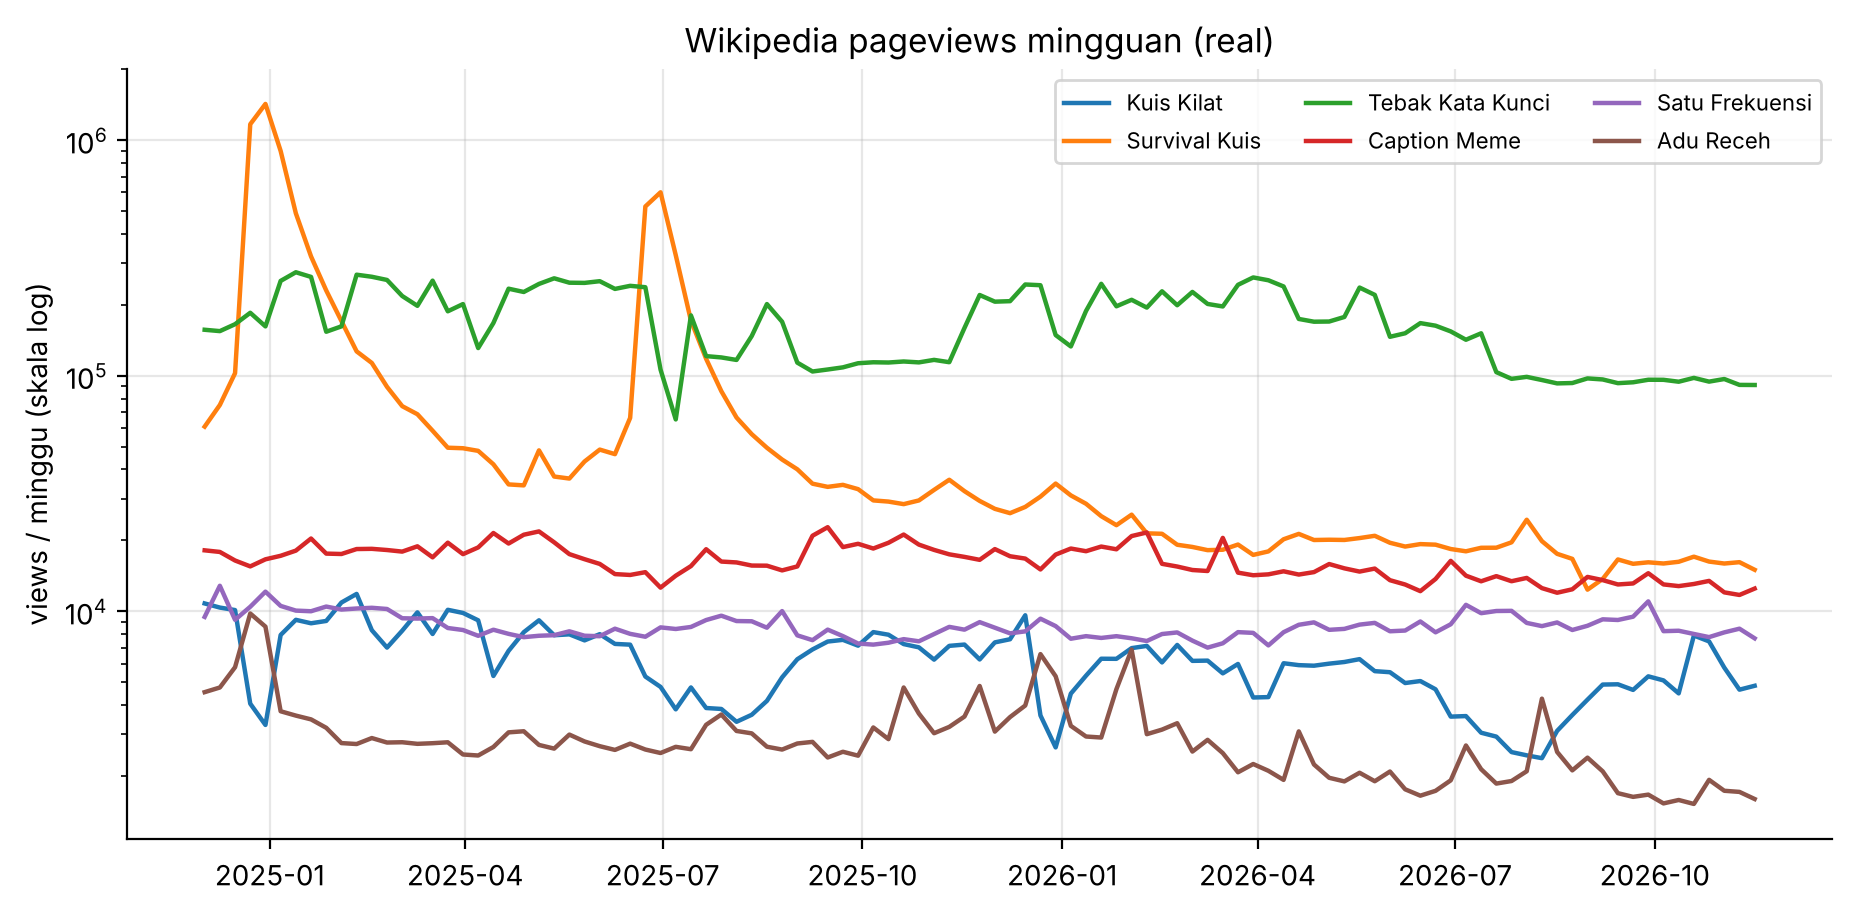

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
for gid in ['kuis_kilat','survival_kuis','tebak_kata_kunci','voting_meme','satu_frekuensi','adu_receh']:
    d = wiki[wiki.game_id == gid]; ax.plot(d.week, d.wiki_views, label=NAMES[gid], lw=1.6)
ax.set_yscale('log'); ax.set_ylabel('views / minggu (skala log)'); ax.set_title('Wikipedia pageviews mingguan (real)'); ax.legend(ncol=3, fontsize=8); plt.show()

**Insight:** skala minat sangat berbeda antar jenis game, dan beberapa punya lonjakan tajam (mis. *Squid Game* saat musim baru tayang). Karena itu ranking memakai **momentum** (dibanding rata-rata 12 minggu sendiri), bukan angka mentah.

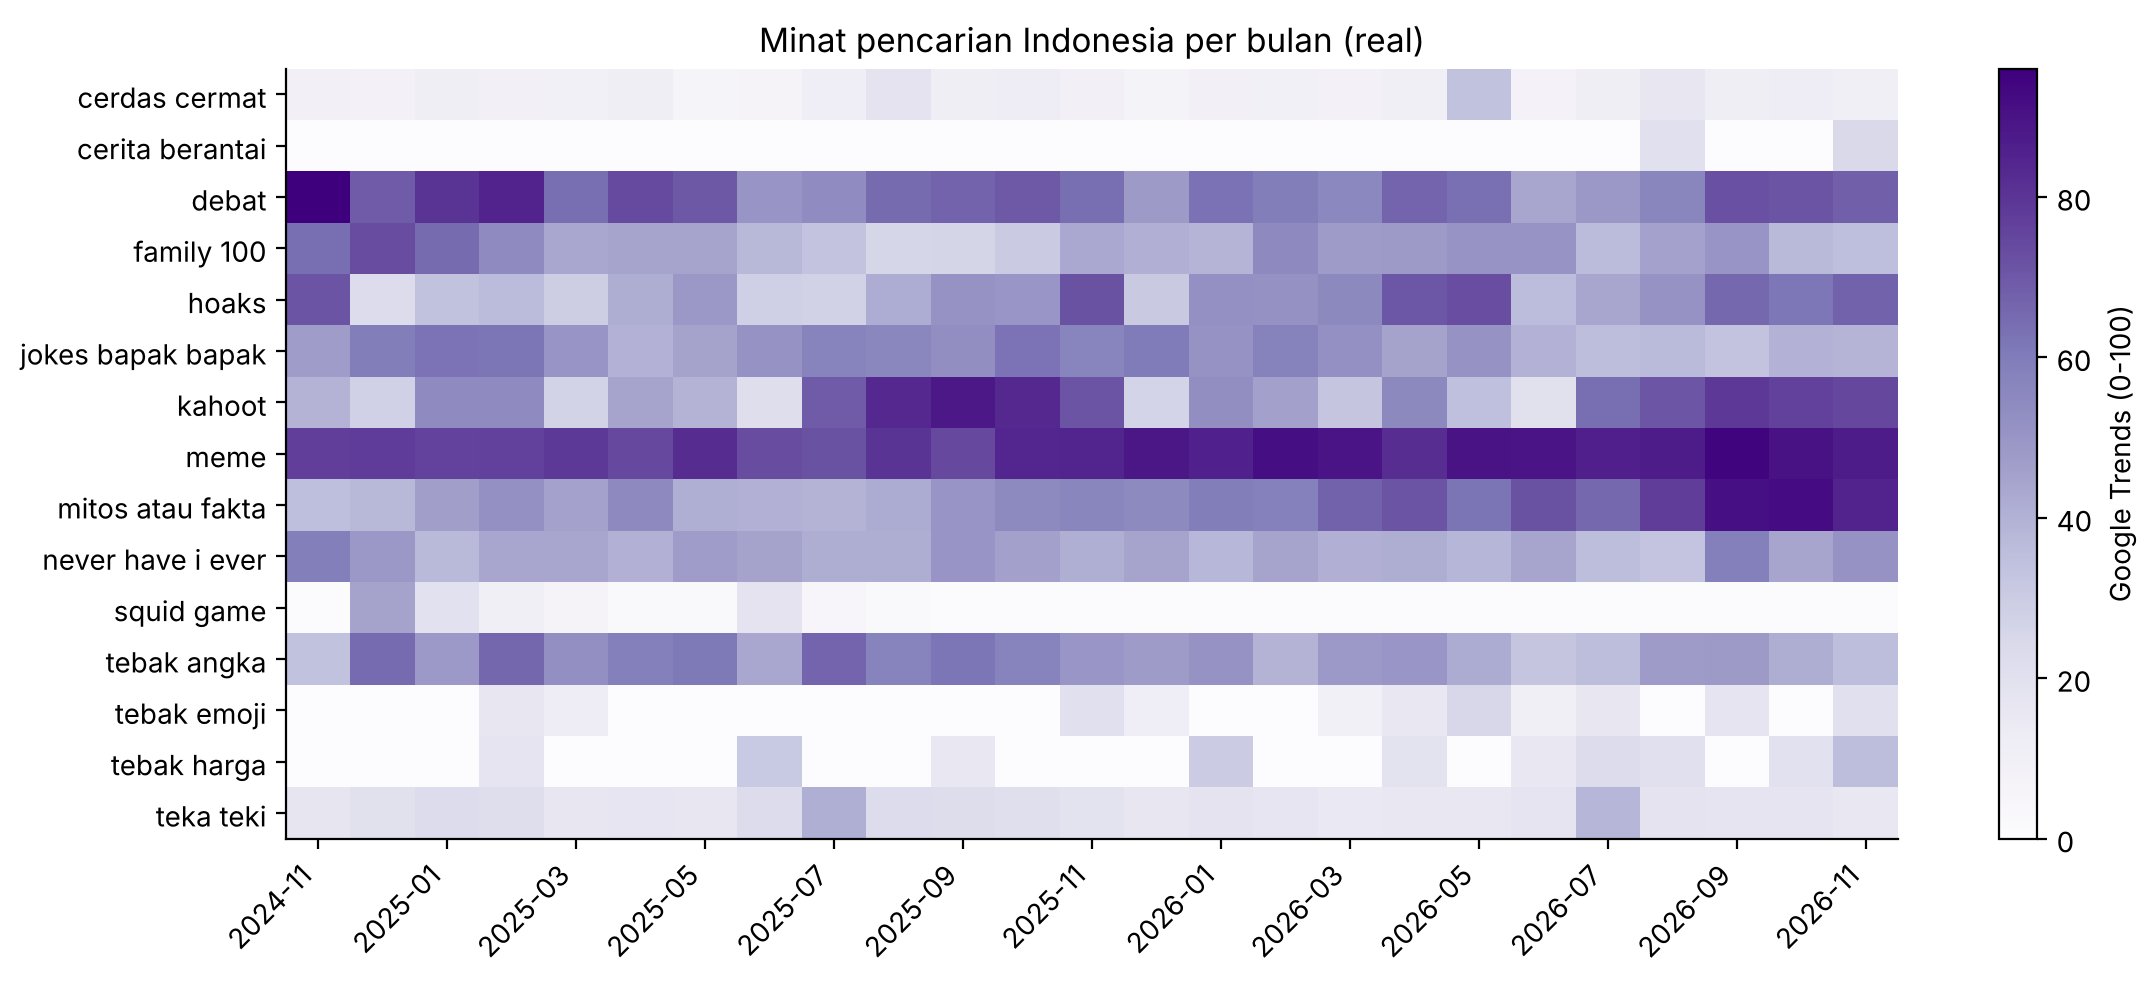

In [9]:
pv = gt.pivot_table(index='keyword', columns=gt.week.dt.to_period('M').astype(str), values='google_trends')
fig, ax = plt.subplots(figsize=(13, 5)); im = ax.imshow(pv.values, aspect='auto', cmap='Purples')
ax.set_yticks(range(len(pv)), pv.index); ax.set_xticks(range(0, pv.shape[1], 2), pv.columns[::2], rotation=45, ha='right')
ax.grid(False); plt.colorbar(im, label='Google Trends (0-100)'); ax.set_title('Minat pencarian Indonesia per bulan (real)'); plt.show()

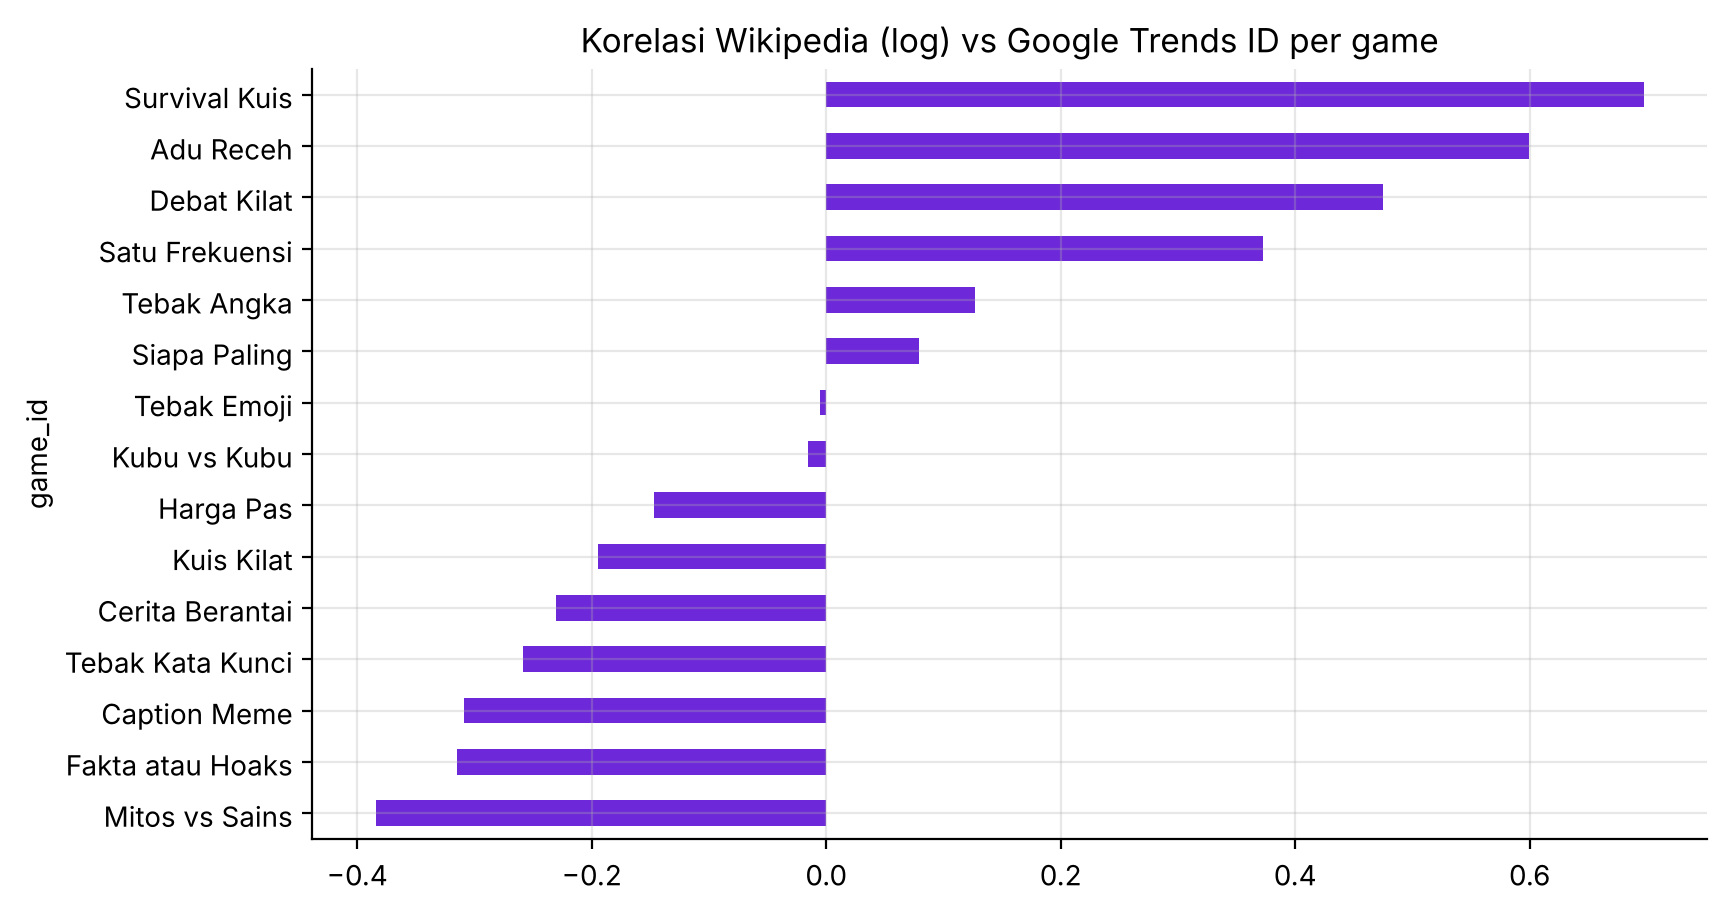

median korelasi: -0.02


In [10]:
m = wiki.merge(gt, on=['week','game_id'])
corr = m.groupby('game_id').apply(lambda d: np.log1p(d.wiki_views).corr(d.google_trends)).rename(NAMES).sort_values()
corr.plot.barh(color='#6D28D9', title='Korelasi Wikipedia (log) vs Google Trends ID per game', figsize=(9,5)); plt.show()
print('median korelasi:', corr.median().round(2))

**Insight:** Wikipedia (global, mayoritas bahasa Inggris) dan Google Trends Indonesia tidak selalu searah. Keduanya dipakai bersama: Wikipedia untuk skala & prediksi, Google Trends untuk konteks Indonesia.

median autokorelasi perubahan mingguan (lag 1): -0.183


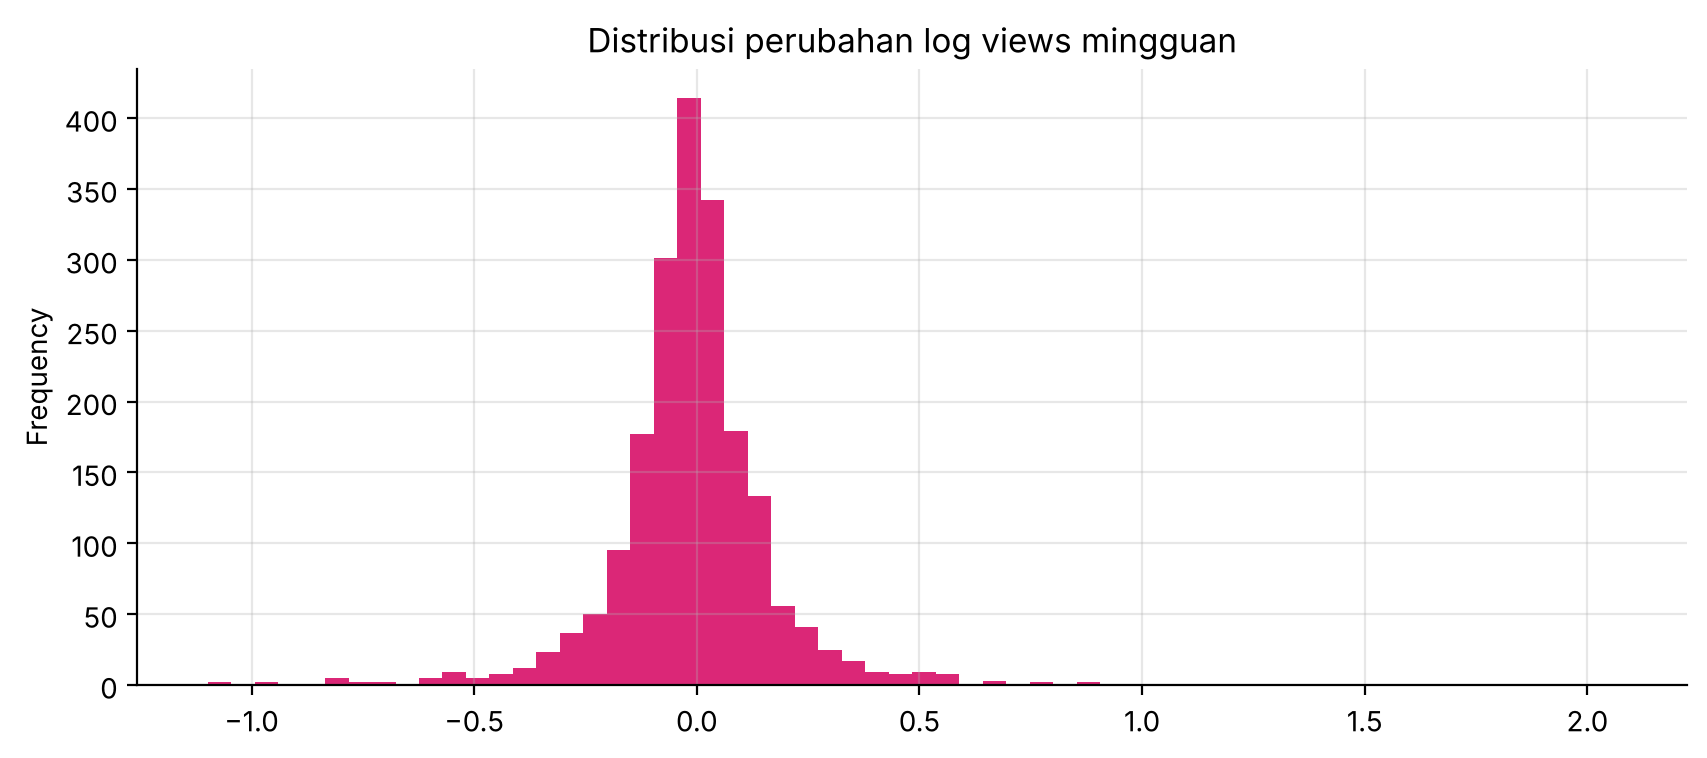

In [11]:
d = panel.assign(delta=panel[TARGET] - panel.lv_t).dropna(subset=['delta'])
ac = d.groupby('game_id').apply(lambda x: x.delta.autocorr(1)).median()
print('median autokorelasi perubahan mingguan (lag 1):', round(ac, 3))
d.delta.plot.hist(bins=60, color='#DB2777', title='Distribusi perubahan log views mingguan'); plt.show()

**Insight penting:** perubahan mingguan cenderung berbalik (autokorelasi negatif = *mean reversion*) dan sebagian besar kecil. Data seperti ini mirip *random walk*, sehingga baseline naive sangat kuat. Ini alasan model memprediksi **perubahan (delta)**, bukan level.

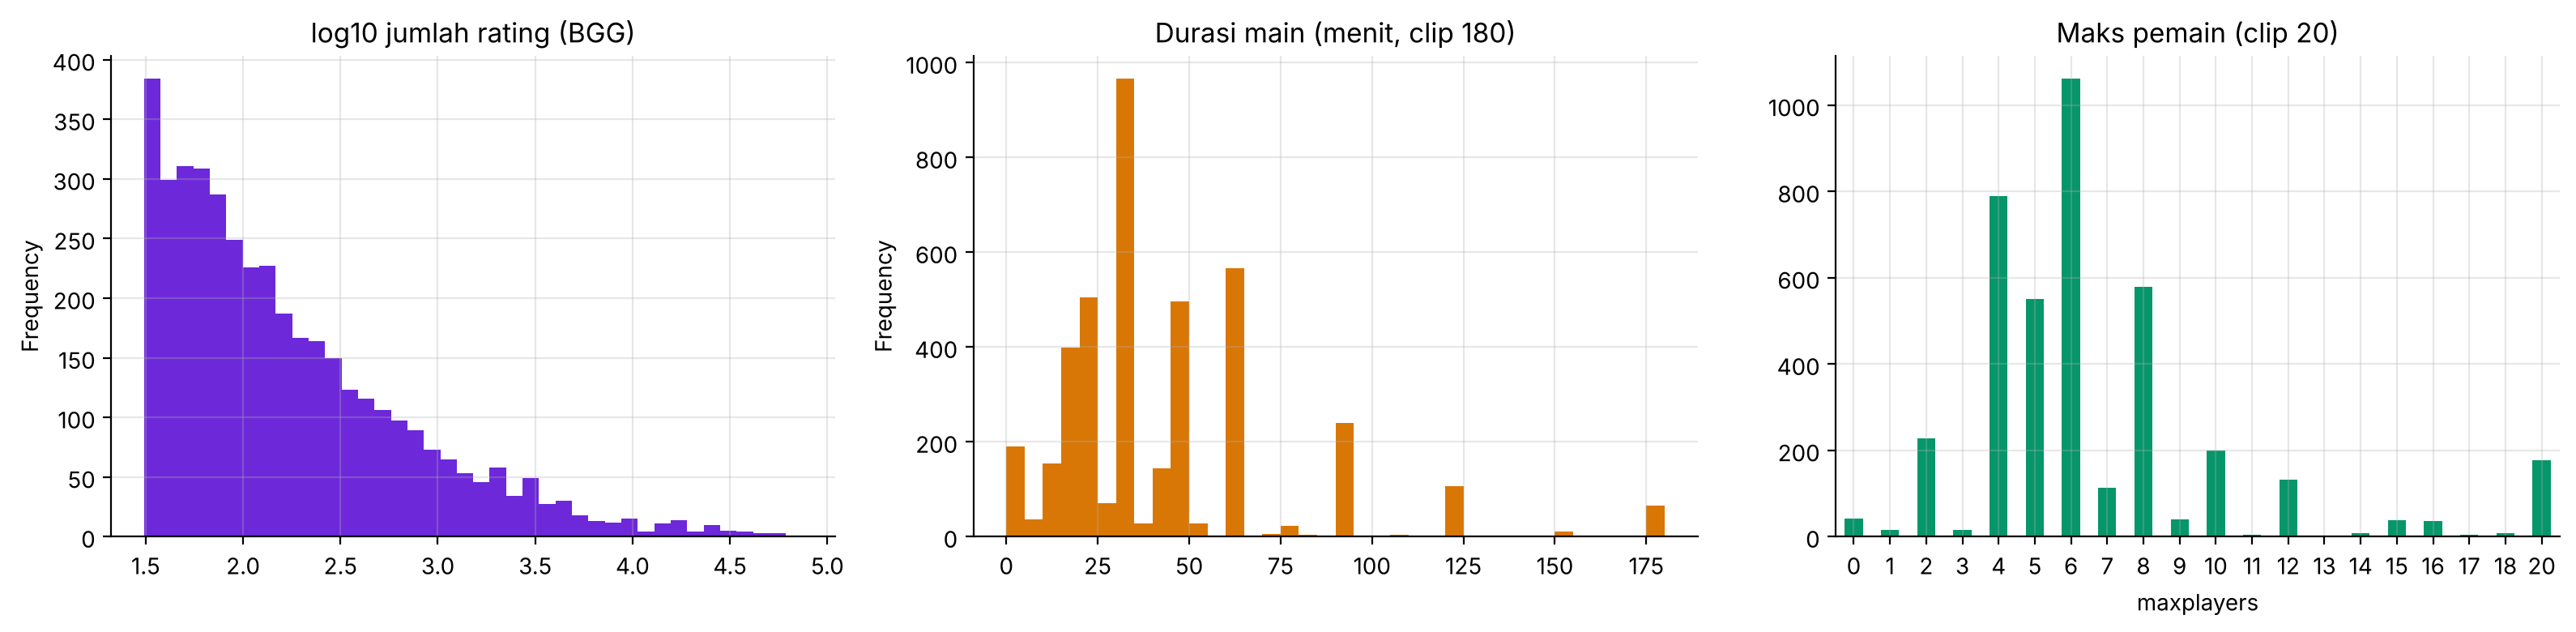

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
b = bgg[bgg.yearpublished.between(2000, 2021)]
np.log10(b.users_rated + 1).plot.hist(bins=40, ax=axs[0], color='#6D28D9', title='log10 jumlah rating (BGG)')
b.playingtime.clip(0, 180).plot.hist(bins=36, ax=axs[1], color='#D97706', title='Durasi main (menit, clip 180)')
b.maxplayers.clip(0, 20).value_counts().sort_index().plot.bar(ax=axs[2], color='#059669', title='Maks pemain (clip 20)', rot=0)
plt.tight_layout(); plt.show()

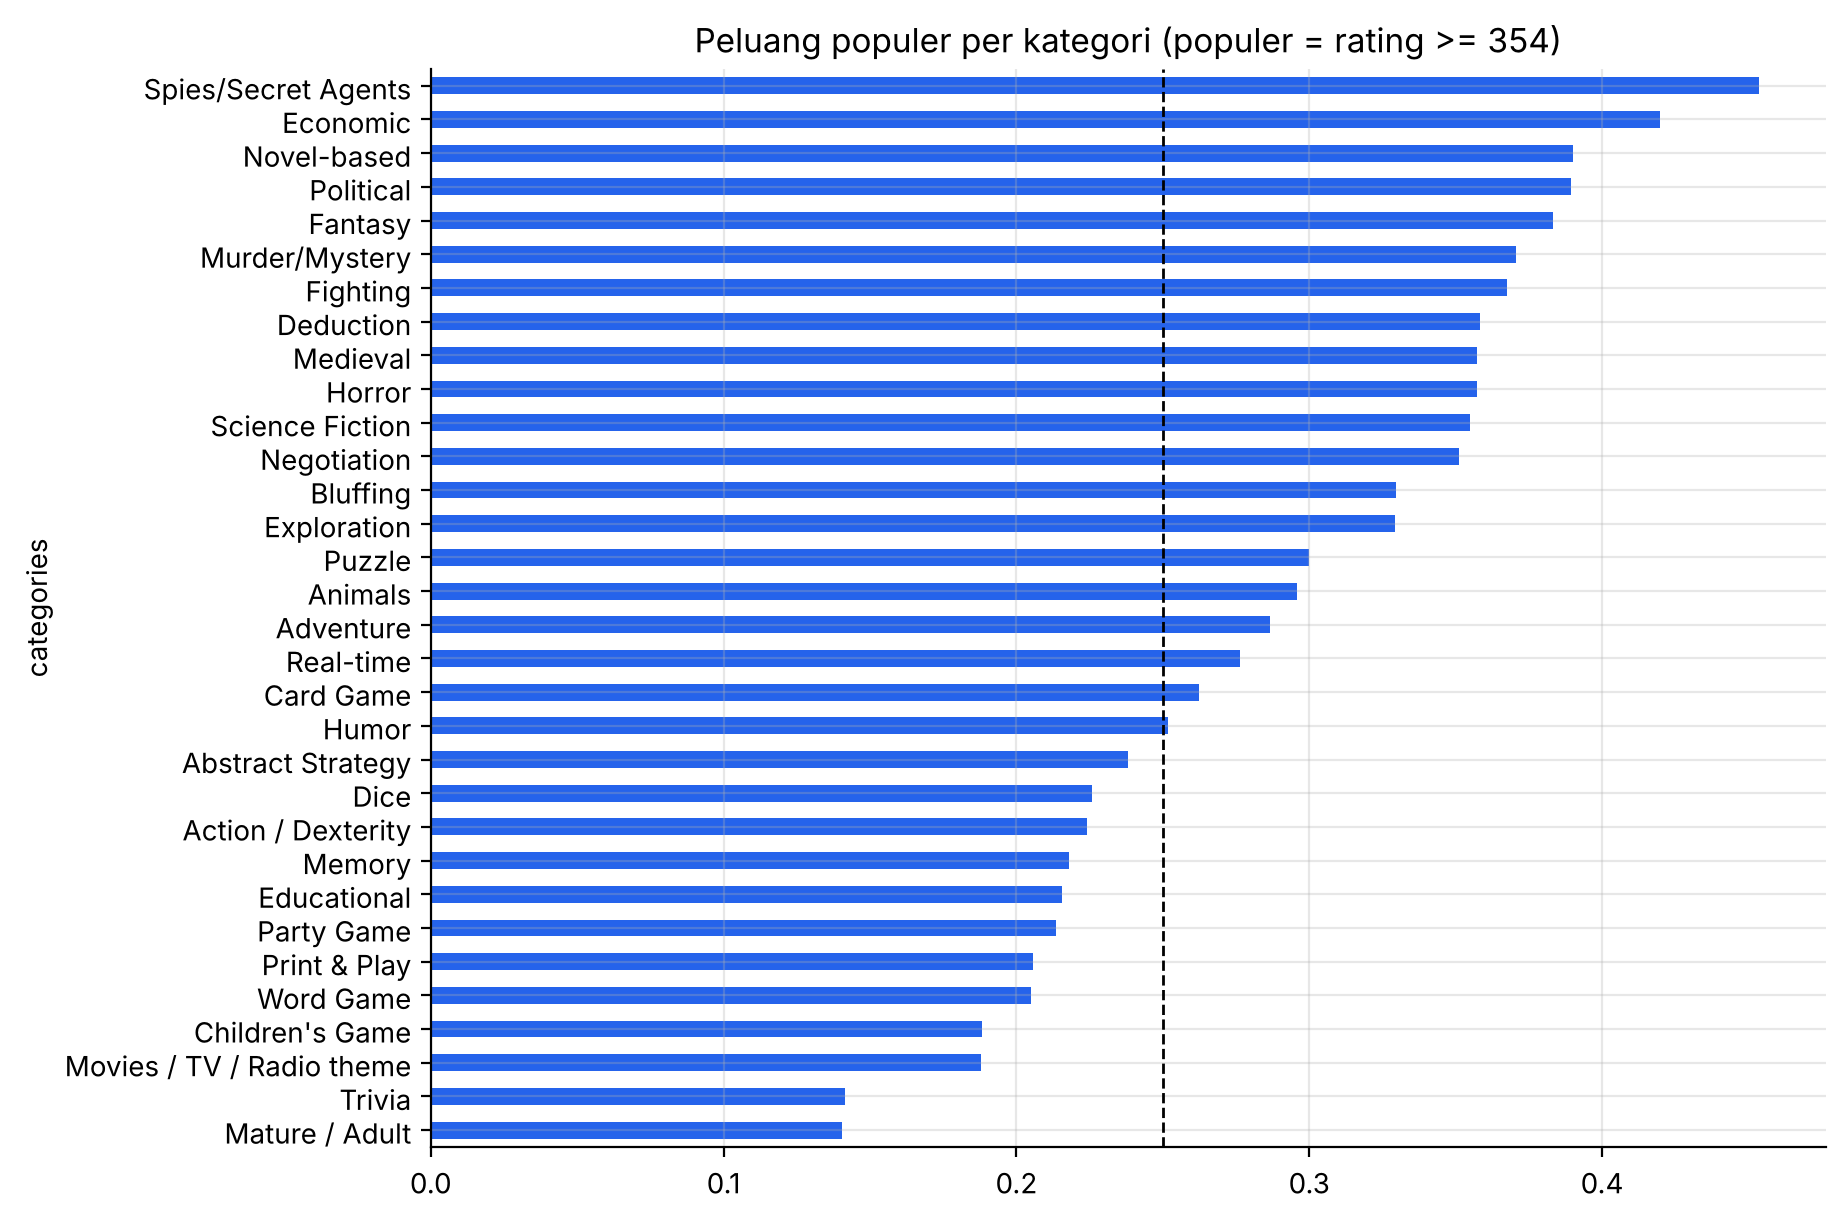

In [13]:
thr = b.users_rated.quantile(.75); b = b.assign(populer=b.users_rated >= thr)
ex = b.explode('categories'); rate = ex.groupby('categories').populer.agg(['mean','size']).query('size >= 80').sort_values('mean')
rate['mean'].plot.barh(color='#2563EB', figsize=(9, 7), title=f'Peluang populer per kategori (populer = rating >= {thr:.0f})'); plt.axvline(.25, color='k', ls='--', lw=1); plt.show()

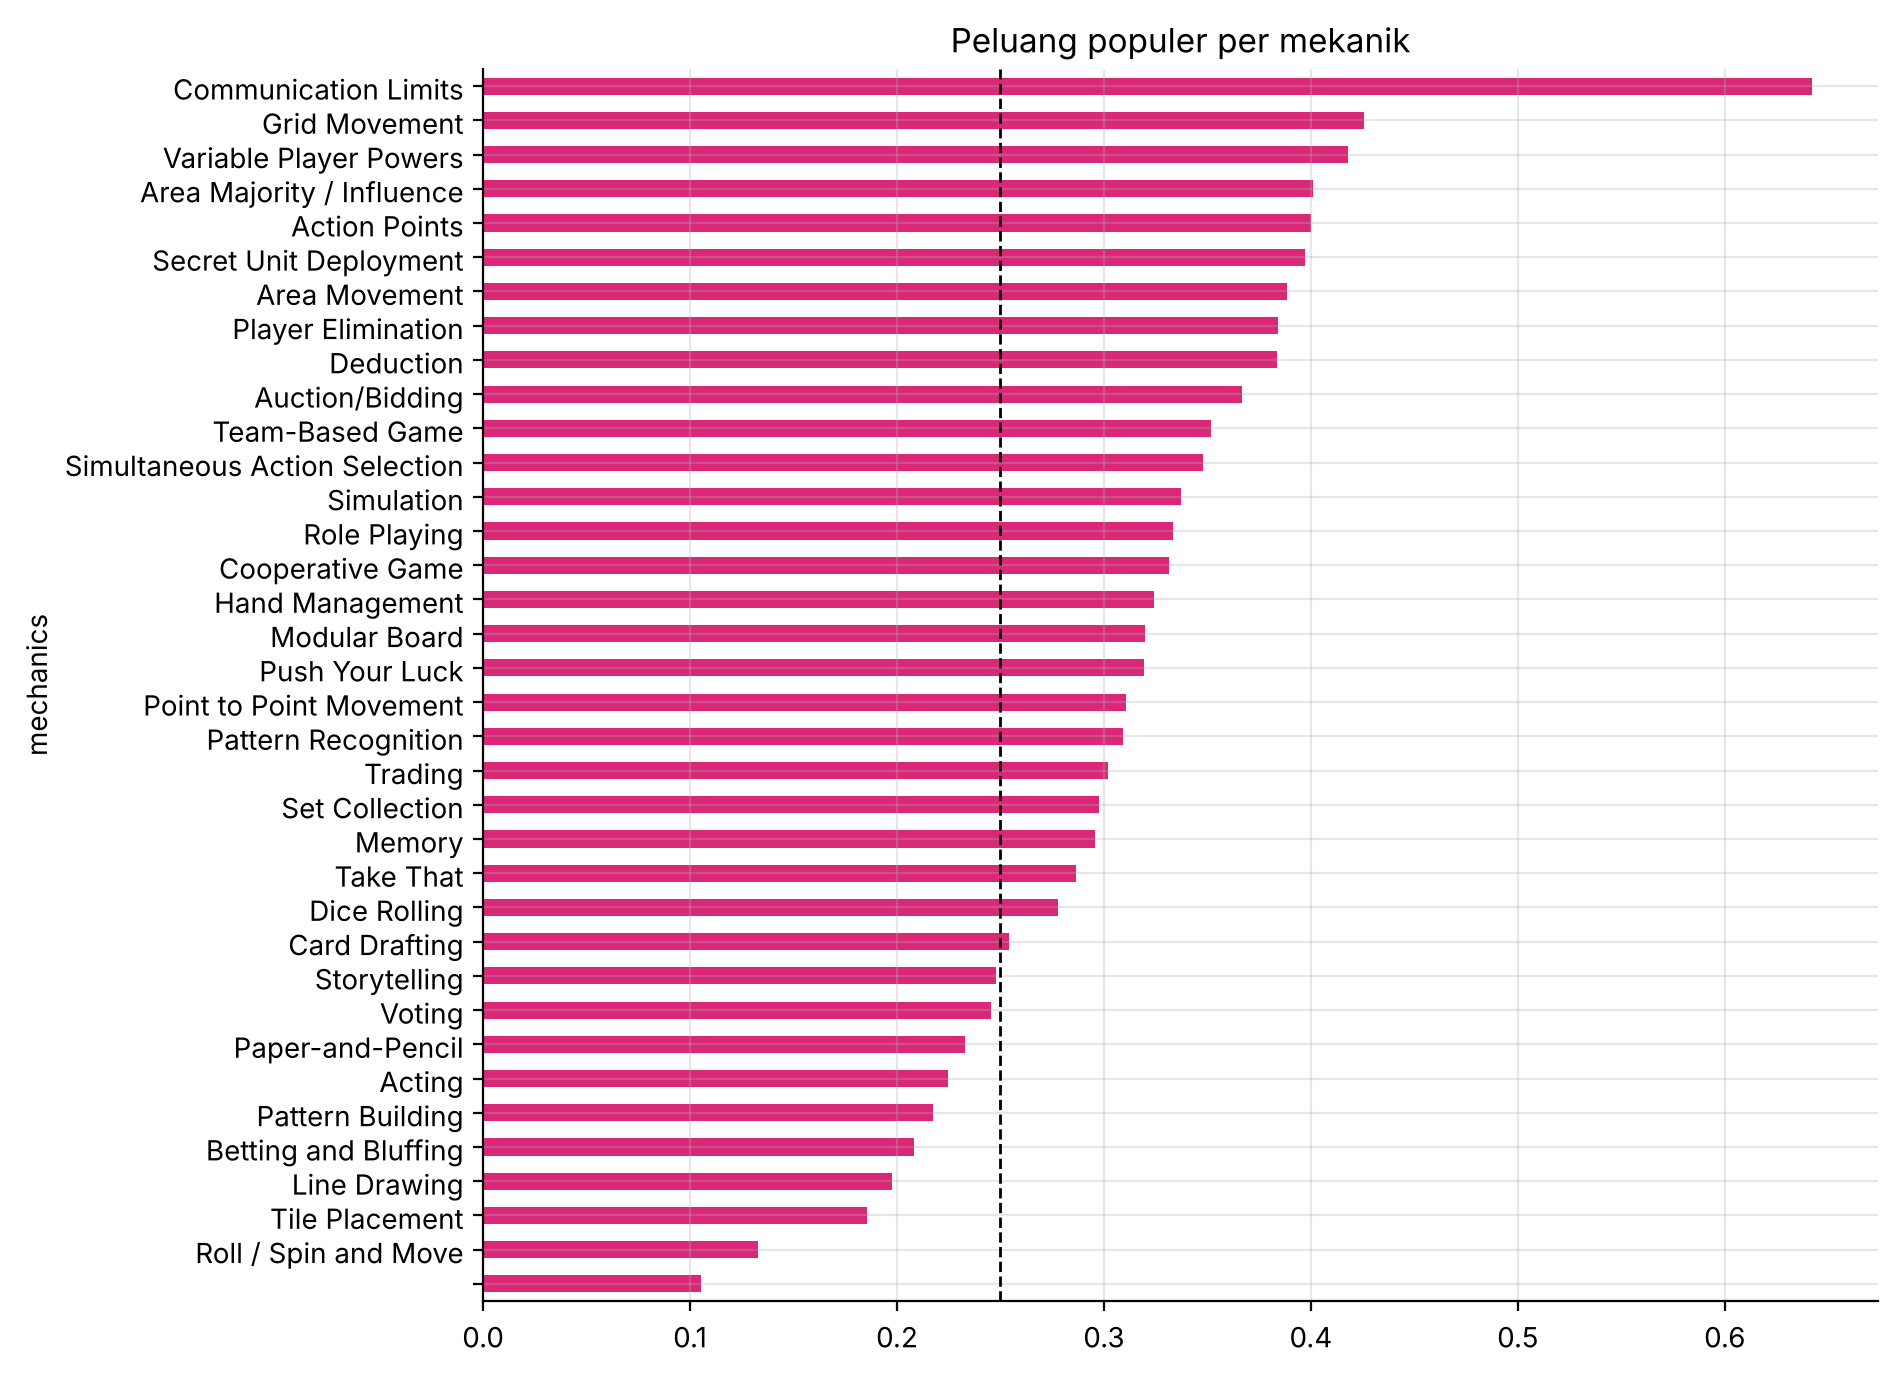

In [14]:
ex = b.explode('mechanics'); rate = ex.groupby('mechanics').populer.agg(['mean','size']).query('size >= 80').sort_values('mean')
rate['mean'].plot.barh(color='#DB2777', figsize=(9, 8), title='Peluang populer per mekanik'); plt.axvline(.25, color='k', ls='--', lw=1); plt.show()

**Insight:** mekanik interaksi sosial (voting, tim, deduksi) dan durasi pendek lebih sering populer di kategori party. Informasi ini yang dipakai model daya tarik untuk menilai game baru.

## 4. Model 1: prediksi tren real (>= 3 model)
Target: perubahan `log(1+views)` minggu depan. Split waktu (20 minggu terakhir = test).
Metrik: MAE log (~error relatif), MAPE views, akurasi arah naik/turun, Precision@10 ranking momentum.

In [15]:
from scripts.train_model import main as train_trend
rep = train_trend()
res = pd.DataFrame(rep['results']).set_index('model'); res

Ridge Regression             MAE_log=0.1150 arah=0.521 P@10=0.835
Huber Regression (robust)    MAE_log=0.1105 arah=0.577 P@10=0.845


Random Forest                MAE_log=0.1104 arah=0.540 P@10=0.840
Gradient Boosting (HistGB)   MAE_log=0.1075 arah=0.555 P@10=0.845


MLP (Neural Net)             MAE_log=0.1254 arah=0.491 P@10=0.825


BEST: Gradient Boosting (HistGB)


,MAE_log,MAPE_views,R2_log,Akurasi_arah,Precision@10_momentum
model,,,,,
Baseline (naive: = minggu ini),0.1130,0.1239,0.9919,0.0024,0.850
Baseline (rata-rata 4 minggu),0.1262,0.1348,0.9918,0.5693,0.820
Ridge Regression,0.1150,0.1253,0.9923,0.5207,0.835
Huber Regression (robust),0.1105,0.1190,0.9925,0.5766,0.845
Random Forest,0.1104,0.1193,0.9931,0.5401,0.840
Gradient Boosting (HistGB),0.1075,0.1159,0.9927,0.5547,0.845
MLP (Neural Net),0.1254,0.1335,0.9912,0.4915,0.825


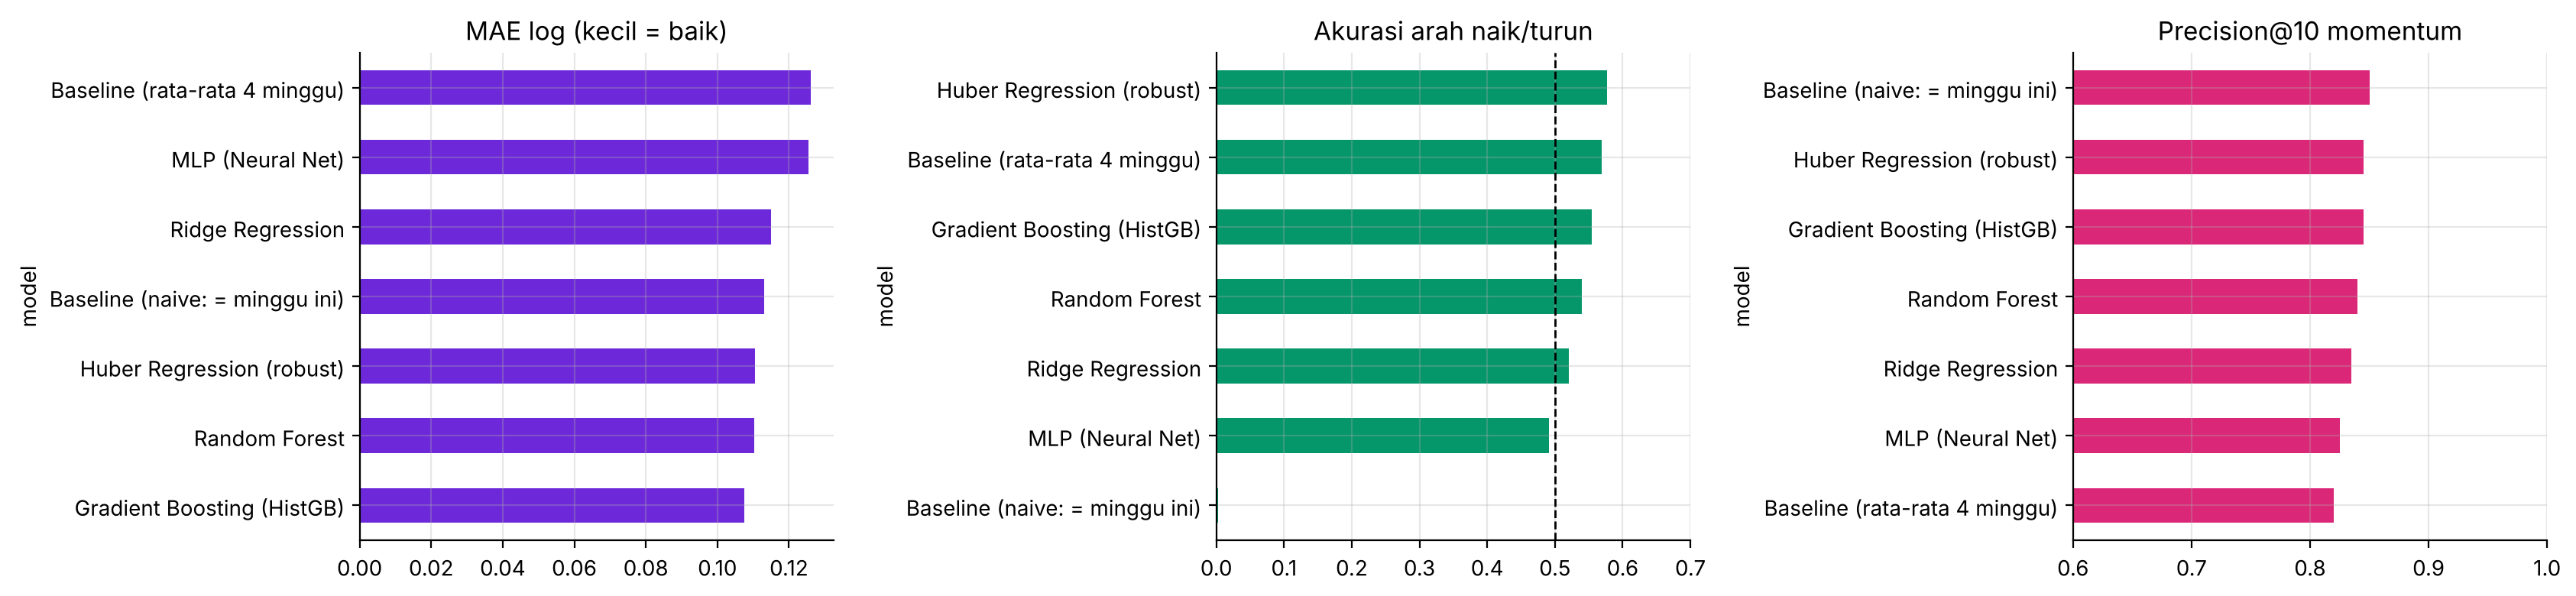

Model terpilih: Gradient Boosting (HistGB)


In [16]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
res['MAE_log'].sort_values().plot.barh(ax=axs[0], color='#6D28D9', title='MAE log (kecil = baik)')
res['Akurasi_arah'].sort_values().plot.barh(ax=axs[1], color='#059669', title='Akurasi arah naik/turun', xlim=(0, .7)); axs[1].axvline(.5, color='k', ls='--', lw=1)
res['Precision@10_momentum'].sort_values().plot.barh(ax=axs[2], color='#DB2777', title='Precision@10 momentum', xlim=(.6, 1))
plt.tight_layout(); plt.show(); print('Model terpilih:', rep['best_model'])

**Interpretasi jujur.** Baseline naive (minggu depan = minggu ini) sudah sangat kuat di data web. Model terpilih
mengalahkan baseline di MAE dan menebak arah naik/turun > 50% (baseline naive tidak bisa menebak arah sama sekali),
sehingga berguna untuk **momentum**, yaitu jenis game mana yang sedang naik daun.

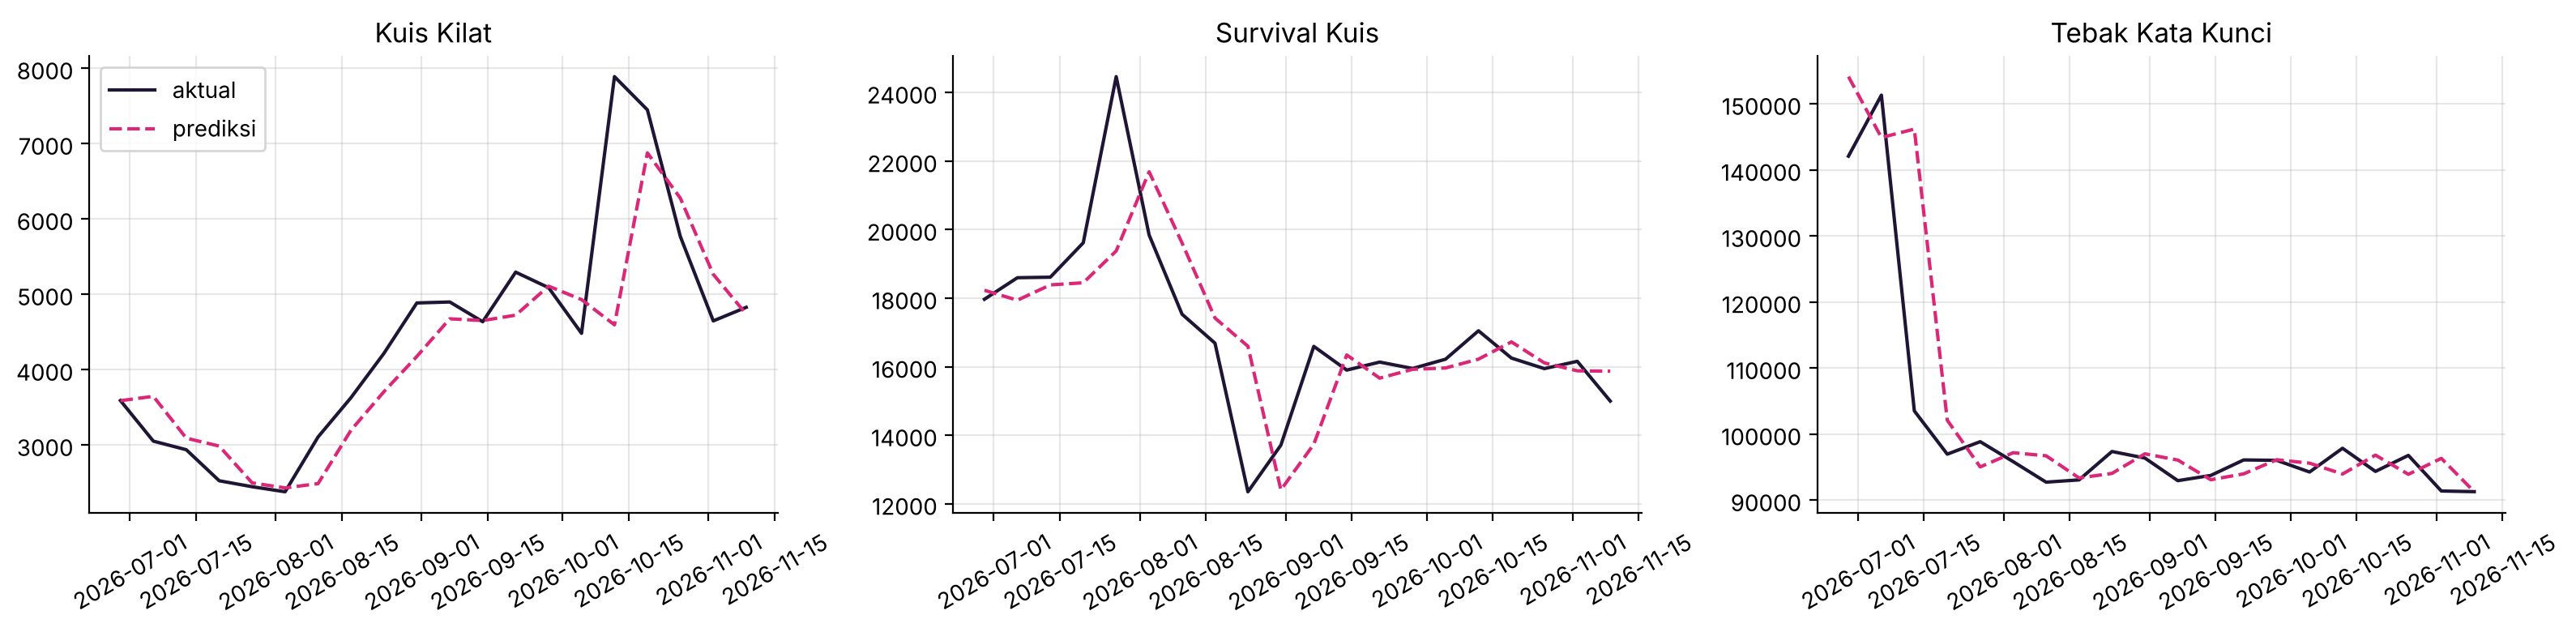

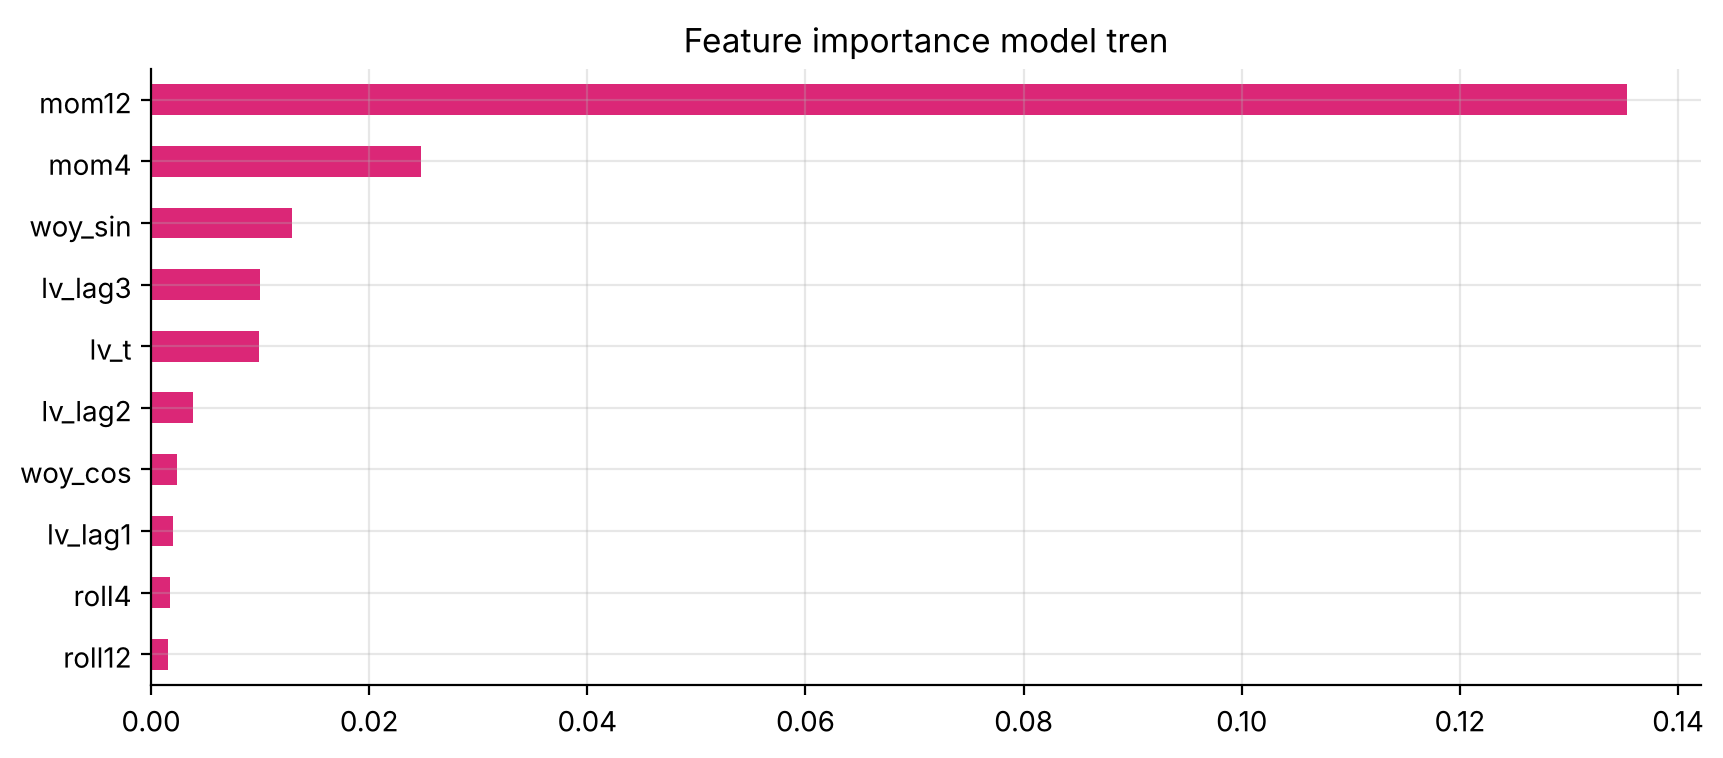

In [17]:
import joblib
from core.config import MODEL_PATH
bundle = joblib.load(MODEL_PATH)
data = panel.dropna(subset=[TARGET]); weeks = sorted(data.week.unique()); test = data[data.week >= weeks[-20]].copy()
test['pred'] = test.lv_t + bundle['model'].predict(test[FEATURES])
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, gid in zip(axs, ['kuis_kilat', 'survival_kuis', 'tebak_kata_kunci']):
    d = test[test.game_id == gid]
    ax.plot(d.week, np.expm1(d[TARGET]), color='#1F1534', label='aktual'); ax.plot(d.week, np.expm1(d.pred), '--', color='#DB2777', label='prediksi')
    ax.set_title(NAMES[gid]); ax.tick_params(axis='x', rotation=30)
axs[0].legend(); plt.tight_layout(); plt.show()
pd.Series(rep['feature_importance']).head(10).sort_values().plot.barh(color='#DB2777', title='Feature importance model tren'); plt.show()

## 5. Model 2: daya tarik game (cold start, data real BGG, >= 3 model)
Klasifikasi: apakah game party dengan profil tertentu (pemain, durasi, usia, kategori, mekanik) masuk 25% teratas
jumlah rating. Evaluasi: Stratified 5-fold CV + holdout.

In [18]:
from scripts.train_appeal_model import main as train_appeal
ap = train_appeal()
pd.DataFrame(ap['results']).set_index('model')

Logistic Regression          CV AUC=0.673 test AUC=0.689


Random Forest                CV AUC=0.699 test AUC=0.720


Gradient Boosting (HistGB)   CV AUC=0.678 test AUC=0.691


MLP (Neural Net)             CV AUC=0.663 test AUC=0.681


BEST: Random Forest


,CV_ROC_AUC,CV_F1,Test_ROC_AUC,Test_F1
model,,,,
Baseline (selalu 'tidak populer'),0.5000,0.0000,0.5000,0.0000
Logistic Regression,0.6731,0.4546,0.6888,0.4911
Random Forest,0.6986,0.4741,0.7202,0.4917
Gradient Boosting (HistGB),0.6785,0.4365,0.6911,0.4286
MLP (Neural Net),0.6630,0.1801,0.6809,0.1459


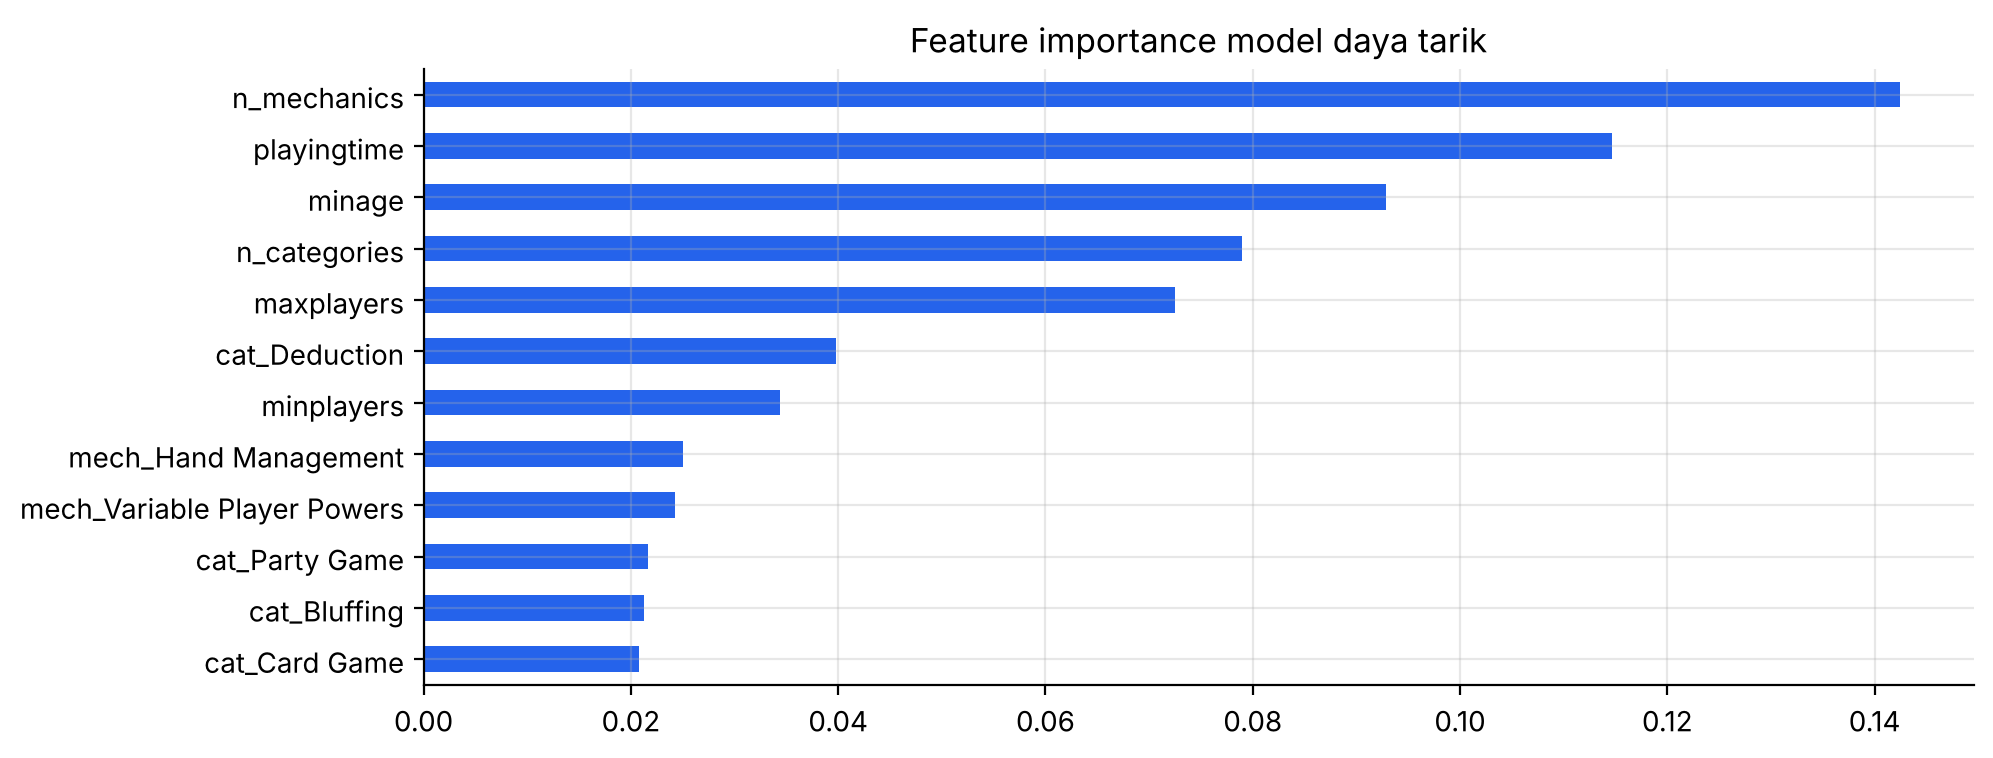

quiz         0.313
truefalse    0.352
majority     0.323
estimate     0.419
open_vote    0.395
Name: P(populer), dtype: float64

In [19]:
pd.Series(ap['feature_importance']).head(12).sort_values().plot.barh(color='#2563EB', title='Feature importance model daya tarik'); plt.show()
from core.appeal import appeal_score
from core.catalog import MECHANICS
pd.Series({m: appeal_score({'mechanic': m, 'max_players': 20, 'rounds': 8, 'seconds_per_round': 20}) for m in MECHANICS}).round(3).rename('P(populer)')

## 6. Skor ranking library
`skor = (1 - w) x [0,65 x tren_real + 0,35 x daya_tarik] + w x request_in_app`

- `tren_real` = 0,40 x momentum prediksi (Wikipedia) + 0,35 x momentum Google Trends ID + 0,25 x level views (semua dalam persentil)
- `daya_tarik` = probabilitas populer dari model BGG (game custom hanya memakai ini + request)
- `w = n / (n + 50)`, maks 0,7, dengan `n` = request in-app 28 hari terakhir. **Mulai dari 0.**

In [20]:
import tempfile, core.library as L, core.storage as S
tmp = Path(tempfile.mkdtemp())
L.RUNTIME_DIR, L.LIBRARY_STATE, L.RUNTIME_REQUESTS = tmp, tmp/'state.json', tmp/'req.csv'
S.RUNTIME_REQUESTS = tmp/'req.csv'; L._pred_cache.clear()
sc = L.compute_scores()
sc[['name','views_t','momentum','gt_mom','appeal','trend_part','w_req','score']].round(3).head(15)

,name,views_t,momentum,gt_mom,appeal,trend_part,w_req,score
0,Tebak Angka,3.0,0.002,1.203,0.408,0.670,0.0,0.774
1,Caption Meme,12484.0,-0.052,0.983,0.389,0.720,0.0,0.748
2,Survival Kuis,14998.0,-0.029,1.091,0.343,0.837,0.0,0.707
3,Harga Pas,5414.0,-0.199,2.623,0.408,0.530,0.0,0.683
4,Cerita Berantai,1618.0,-0.131,5.667,0.389,0.600,0.0,0.670
5,Adu Receh,1596.0,-0.075,0.844,0.389,0.460,0.0,0.579
6,Fakta atau Hoaks,617.0,-0.094,1.062,0.350,0.513,0.0,0.520
7,Tebak Emoji,7585.0,-0.112,2.400,0.313,0.673,0.0,0.484
8,Tebak Kata Kunci,91291.0,-0.047,0.812,0.313,0.617,0.0,0.448
9,Debat Kilat,921.0,-0.146,0.845,0.389,0.307,0.0,0.433


## 7. SIMULASI (bukan data real): bagaimana request in-app menggeser ranking
Log request in-app masih nol saat notebook ini dibuat. Bagian ini **mensimulasikan** 0 sampai 300 request
(mis. komunitas yang sering memilih *Siapa Paling*) untuk menunjukkan bobot `w` naik dan ranking bergeser.

 request_simulasi  w_request  ranking_siapa_paling
                0      0.000                    15
               10      0.167                    10
               25      0.333                     2
               50      0.500                     1
              100      0.667                     1
              200      0.700                     1
              300      0.700                     1


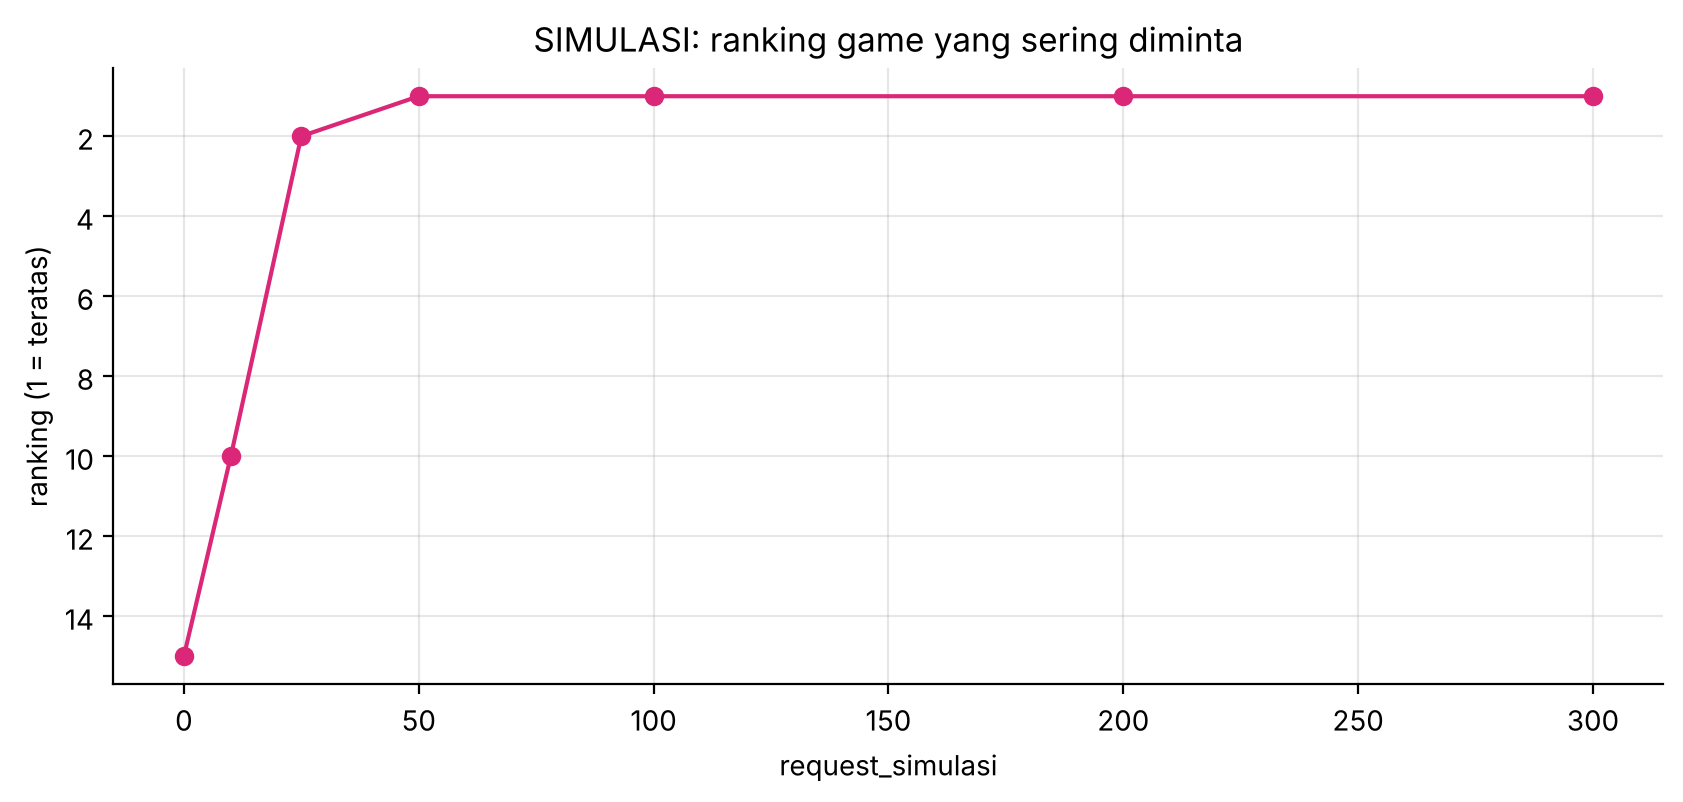

In [21]:
rows = []
target = 'siapa_paling'
rng = np.random.default_rng(0); others = [g['id'] for g in GAMES if g['id'] != target]
done = 0
for n in [0, 10, 25, 50, 100, 200, 300]:
    while done < n:
        L.log_request(target if rng.random() < .4 else rng.choice(others), {'players': 10}); done += 1
    s = L.compute_scores()
    rows.append({'request_simulasi': n, 'w_request': s.w_req.iloc[0], 'ranking_siapa_paling': int(s.index[s.game_id == target][0]) + 1})
sim = pd.DataFrame(rows); print(sim.to_string(index=False))
ax = sim.plot(x='request_simulasi', y='ranking_siapa_paling', marker='o', color='#DB2777', legend=False, title='SIMULASI: ranking game yang sering diminta')
ax.invert_yaxis(); ax.set_ylabel('ranking (1 = teratas)'); plt.show()

## 8. Validasi ground truth: apakah Top-10 masih sama?
Setiap update (otomatis tiap Senin via GitHub Actions), ground truth menghitung Top-10 baru dan membandingkan dengan
versi sebelumnya: overlap, Kendall tau, game masuk/keluar. **STABIL** jika overlap >= 8/10.
Di bawah ini replay mingguan selama periode test dengan data real (komponen tren saja, tanpa request in-app).

{'STABIL': 19, 'BASELINE': 1}


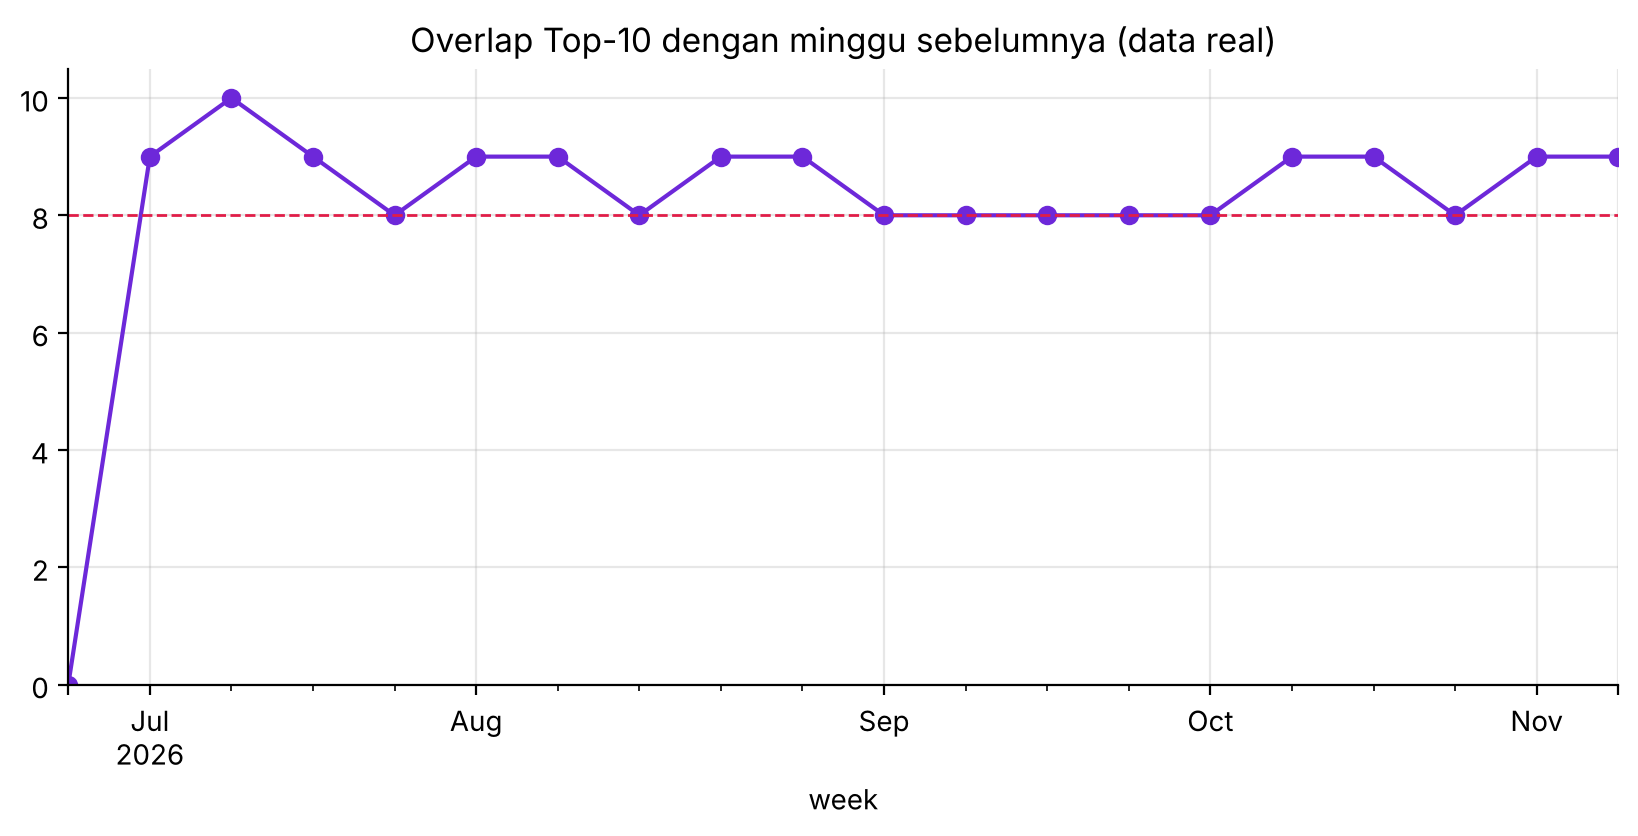

,week,overlap,verdict,masuk
12,2026-09-21,8,STABIL,"harga_pas,tim_vs_tim"
13,2026-09-28,8,STABIL,"tebak_angka,survival_kuis"
14,2026-10-05,8,STABIL,"debat_kilat,fakta_hoaks"
15,2026-10-12,9,STABIL,harga_pas
16,2026-10-19,9,STABIL,mitos_sains
17,2026-10-26,8,STABIL,"siapa_paling,adu_receh"
18,2026-11-02,9,STABIL,satu_frekuensi
19,2026-11-09,9,STABIL,tim_vs_tim


In [22]:
from core.ground_truth import compare
cat = test[test.game_id.isin(GAME_BY_ID)].copy(); cat['mom'] = cat.pred - cat.roll12
snaps, prev = [], []
for w, d in cat.groupby('week'):
    d = d.assign(s=d.mom.rank(pct=True) * .6 + d.lv_t.rank(pct=True) * .4)
    top = list(d.nlargest(10, 's').game_id); c = compare(prev, top)
    snaps.append({'week': w, 'overlap': c['overlap'], 'verdict': c['verdict'], 'masuk': ','.join(c['masuk']) if prev else ''})
    prev = top
gt_sim = pd.DataFrame(snaps); print(gt_sim.verdict.value_counts().to_dict())
ax = gt_sim.set_index('week').overlap.plot(marker='o', color='#6D28D9', ylim=(0, 10.5), title='Overlap Top-10 dengan minggu sebelumnya (data real)')
ax.axhline(8, color='#E11D48', ls='--', lw=1); plt.show(); gt_sim.tail(8)

## 9. Generative AI: agent LangChain
**Komponen (semua lewat `core/llm.py`, satu-satunya tempat API key dipakai):**
1. **Agent Game Master** (`langchain.agents.create_agent`, ReAct di atas LangGraph) dengan 7 tools:
   `get_trends`, `recommend_games`, `read_document`, `design_custom_game`, `validate_custom_game`,
   `register_custom_game`, `create_room`.
2. **Chain Desainer**: ide bebas -> `GameSpec` (Pydantic) -> validasi aturan kunci.
3. **Chain Konten**: potongan dokumen (retrieval TF-IDF, maks 4 potongan) -> `RoundsOut` (Pydantic).

**Pengaman:** ModelFallback (Gemini -> OpenAI), maks 6 panggilan LLM per pesan, `create_room` maks 1x per pesan,
total tool call maks 8, output token maks 1.500, temperature rendah, dan semua angka/link harus berasal dari tool.
Tanpa API key, planner offline memanggil tools yang sama.

In [23]:
from core.documents import parse_bytes
from core.generator import generate_rounds
doc = parse_bytes('materi_pemilahan_sampah.md', (ROOT/'samples/materi_pemilahan_sampah.md').read_bytes())
for gid in ['kuis_kilat', 'fakta_hoaks', 'tebak_angka']:
    rounds, meta = generate_rounds(doc, GAME_BY_ID[gid], 2, 'sampah', use_llm=False)
    print(f"[{NAMES[gid]}] sumber={meta['provider']}")
    for r in rounds: print('   ', json.dumps(r, ensure_ascii=False)[:170])

[Kuis Kilat] sumber=offline
    {"q": "Lengkapi: Bank sampah adalah tempat ____ menabung sampah anorganik yang sudah dipilah.", "options": ["materi", "warga", "botol", "kuning"], "answer": 1}
    {"q": "Lengkapi: Jadwal pengangkutan sampah ____ dilakukan 2 kali seminggu.", "options": ["desa", "kaleng", "sosialisasi", "tahun"], "answer": 0}
[Fakta atau Hoaks] sumber=offline
    {"q": "Sampah ditimbang, dicatat, lalu dihargai dengan uang sesuai jenisnya.", "answer": true, "explain": "Sesuai materi."}
    {"q": "Karena itu, memilah sampah organik di rumah sangat mengurangi hijau TPA.", "answer": false, "explain": "Seharusnya 'beban', bukan 'hijau'."}
[Tebak Angka] sumber=offline
    {"q": "Botol plastik membutuhkan waktu sekitar **berapa?** tahun untuk terurai di alam.", "answer": 450.0, "unit": ""}
    {"q": "Di Indonesia, sekitar **berapa?** sampah rumah tangga adalah sisa makanan.", "answer": 40.0, "unit": "%"}


In [24]:
# demo loop agent LangChain dengan model palsu (tanpa API key) untuk memperlihatkan alur tool-calling
from langchain_core.language_models.fake_chat_models import GenericFakeChatModel
from langchain_core.messages import AIMessage
from core.agent import AgentContext, build_tools, SYSTEM
from core.lc_agent import run_agent
class Fake(GenericFakeChatModel):
    def bind_tools(self, tools, **kw): return self
tmp2 = Path(tempfile.mkdtemp())   # state bersih: buang request simulasi bagian 7
L.RUNTIME_DIR, L.LIBRARY_STATE, L.RUNTIME_REQUESTS = tmp2, tmp2/'state.json', tmp2/'req.csv'
S.RUNTIME_REQUESTS = tmp2/'req.csv'; L._pred_cache.clear()
script = iter([AIMessage('', tool_calls=[{'name': 'recommend_games', 'args': {'players': 20, 'duration_min': 30, 'event_type': 'sosialisasi desa'}, 'id': '1'}]),
               AIMessage('', tool_calls=[{'name': 'create_room', 'args': {'game_id': 'fakta_hoaks', 'players': 20}, 'id': '2'}]),
               AIMessage('Room siap, ini link host & peserta.')])
ctx = AgentContext(base_url='https://ai-game-generator.streamlit.app', doc=doc, use_llm=False)
answer, trace = run_agent([Fake(messages=script)], build_tools(ctx), SYSTEM, [{'role': 'user', 'content': 'sosialisasi desa 20 warga 30 menit'}])
for t in trace: print(t['tool'], '->', {k: t['result'][k] for k in list(t['result'])[:3]})
print(answer)

recommend_games -> {'params': {'players': 20, 'duration_min': 30, 'event_type': 'sosialisasi desa', 'mode': 'offline', 'location': '', 'topic': ''}, 'recommendations': [{'game_id': 'survival_kuis', 'name': 'Survival Kuis', 'mechanic': 'quiz', 'score': 0.765, 'trend_score': 70.7, 'reasons': ['cocok untuk acara sosialisasi desa']}, {'game_id': 'fakta_hoaks', 'name': 'Fakta atau Hoaks', 'mechanic': 'truefalse', 'score': 0.726, 'trend_score': 54.4, 'reasons': ['cocok untuk acara sosialisasi desa']}, {'game_id': 'tebak_angka', 'name': 'Tebak Angka', 'mechanic': 'estimate', 'score': 0.721, 'trend_score': 76.2, 'reasons': ['lagi rame minggu ini']}]}
create_room -> {'room_code': 'PAVPV', 'game': 'Fakta atau Hoaks', 'rounds': 15}
Room siap, ini link host & peserta.


## 10. Kesimpulan
1. Data real (Wikipedia + Google Trends) menunjukkan minat mingguan mirip random walk; model tren (delta) tetap
   mengalahkan baseline dan berguna untuk mendeteksi **momentum** jenis game.
2. Data real BoardGameGeek memberi model daya tarik (ROC-AUC ~0,7) untuk **cold start** game baru/custom.
3. Log request in-app dimulai dari nol; bobotnya naik otomatis, sehingga ranking makin mencerminkan pemakaian nyata.
4. Ground truth tunggal, diperbarui tiap minggu oleh GitHub Actions, membuat keputusan library bisa diaudit (STABIL/BERUBAH).
5. Agent LangChain dengan 7 tools dan pengaman pemakaian API mengubah permintaan sehari-hari jadi room siap main.

**Saran:** tambah sumber Indonesia lain (YouTube Data API, dengan key gratis), kumpulkan rating per ronde untuk
mengukur kualitas soal, dan pindahkan state room ke database bila pemain > 30.